# 08 – Ensemble & final comparison

Each model notebook (04-07) saved its predictions for the validation and the test set in `results/predictions/`.
Here we:
1. compare all models with the baseline on the validation set
2. check how *different* the models' predictions are (an ensemble only helps if they differ)
3. combine them: **rank averaging** and **stacking**
4. write the Kaggle submission file

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

from utils import baseline_auc

# same plot style as in the other notebooks
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#52514e"
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]  # one fixed colour per model
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": GREY, "xtick.color": GREY, "ytick.color": GREY,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "figure.dpi": 110,
})

MODELS = {"logreg": "Logistic regression", "random_forest": "Random Forest",
          "gradient_boosting": "Gradient boosting", "ft_transformer": "FT-Transformer"}

# true labels of the validation songs
train = pd.read_csv("train.csv").merge(pd.read_csv("results/splits.csv"), on="id")
valid = train[train["is_valid"] == 1]

# one column per model: its predicted hit probability, rows in the same order as 'valid'
valid_preds = pd.DataFrame({name: pd.read_csv(f"results/predictions/{key}_valid.csv")["pred"].values
                            for key, name in MODELS.items()})
test_ids = pd.read_csv("results/predictions/logreg_test.csv")["id"]
test_preds = pd.DataFrame({name: pd.read_csv(f"results/predictions/{key}_test.csv")["pred"].values
                           for key, name in MODELS.items()})

y_valid = valid["music_hit"].values
assert (pd.read_csv("results/predictions/logreg_valid.csv")["id"].values == valid["id"].values).all()  # same row order
BASELINE = baseline_auc()
valid_preds.head()

,Logistic regression,Random Forest,Gradient boosting,FT-Transformer
0,0.010419,0.006065,0.005035,0.002394
1,0.005440,0.005881,0.002217,0.001097
2,0.653923,0.548028,0.407741,0.525401
3,0.671864,0.559544,0.362589,0.556853
4,0.643499,0.545634,0.350946,0.533285


## 1. Single models vs. baseline

In [2]:
results = {name: roc_auc_score(y_valid, valid_preds[name]) for name in MODELS.values()}
pd.Series(results).sort_values(ascending=False).round(4).to_frame("validation AUC")

,validation AUC
Gradient boosting,0.9706
FT-Transformer,0.9678
Random Forest,0.9663
Logistic regression,0.9597


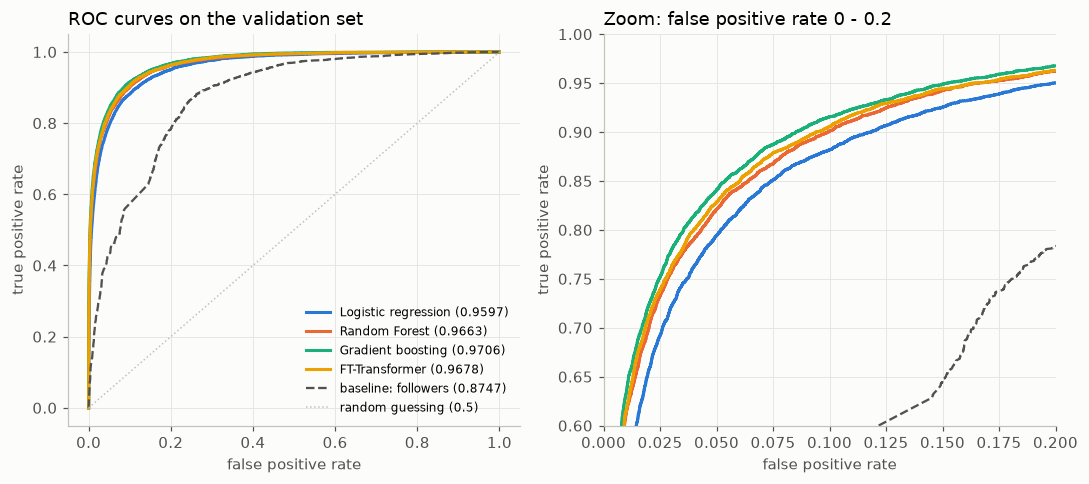

In [3]:
# ROC curves: true positive rate vs false positive rate for every threshold
# left = full curve, right = zoom into the top-left corner where the models differ
fig, (ax_full, ax_zoom) = plt.subplots(1, 2, figsize=(10, 4.5))
for ax in (ax_full, ax_zoom):
    for color, name in zip(SERIES_COLORS, MODELS.values()):
        fpr, tpr, _ = roc_curve(y_valid, valid_preds[name])
        ax.plot(fpr, tpr, color=color, lw=2, label=f"{name} ({results[name]:.4f})")
    # the baseline: artist_followers used directly as the score
    fpr, tpr, _ = roc_curve(y_valid, valid["artist_followers"])
    ax.plot(fpr, tpr, color=GREY, lw=1.5, ls="--", label=f"baseline: followers ({BASELINE:.4f})")
    ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")

ax_full.plot([0, 1], [0, 1], color="#c3c2b7", lw=1, ls=":", label="random guessing (0.5)")
ax_full.legend(frameon=False, loc="lower right", fontsize=8)
ax_full.set_title("ROC curves on the validation set", loc="left")
ax_zoom.set_xlim(0, 0.2); ax_zoom.set_ylim(0.6, 1.0)
ax_zoom.set_title("Zoom: false positive rate 0 - 0.2", loc="left")
plt.tight_layout()
plt.show()

## 2. How different are the models?
AUC only depends on the **ranking** of the songs, so we compare the models' rankings (Spearman correlation).
A correlation of 1.0 means two models rank the songs identically, and averaging them would change nothing.

In [4]:
valid_preds.corr(method="spearman").round(3)

,Logistic regression,Random Forest,Gradient boosting,FT-Transformer
Logistic regression,1.000,0.892,0.916,0.910
Random Forest,0.892,1.000,0.905,0.897
Gradient boosting,0.916,0.905,1.000,0.936
FT-Transformer,0.910,0.897,0.936,1.000


**Interpretation.** All models agree a lot (correlations of 0.89 to 0.94), because they all lean on the same
strong features (album/label/artist hit rate, followers). Gradient boosting and the FT-Transformer are the most similar pair (0.94).
The Random Forest differs most from the others, but it is also weaker. Little diversity means an ensemble has little room to help.

## 3. Combining the models

**Rank averaging.** The models' probabilities aren't on the same scale (a Random Forest rarely outputs values near 0 or 1).
So we first turn each model's predictions into **ranks** (0 = least likely hit, 1 = most likely hit) and average those ranks.
Since AUC only looks at the ranking, this is the natural way to average for this metric.

**Stacking.** Instead of equal weights, a small logistic regression *learns* how much to trust each model.
It must be trained on predictions the models made for songs they did **not** train on, so we use the validation set.
To still measure it honestly, we use 5-fold cross-validation **inside** the validation set.

In [5]:
def to_ranks(preds):
    """Each column -> percentile rank between 0 and 1."""
    return preds.rank(pct=True)

valid_ranks, test_ranks = to_ranks(valid_preds), to_ranks(test_preds)

# rank average of all 4 models, and of the 2 strongest models
all_models = list(MODELS.values())
best_two = ["Gradient boosting", "FT-Transformer"]
ensembles = {
    "Rank average (all 4)": valid_ranks[all_models].mean(axis=1),
    "Rank average (GB + FT-Transformer)": valid_ranks[best_two].mean(axis=1),
}
for name, pred in ensembles.items():
    results[name] = roc_auc_score(y_valid, pred)
    print(f"{name:38s} AUC = {results[name]:.4f}")

Rank average (all 4)                   AUC = 0.9691
Rank average (GB + FT-Transformer)     AUC = 0.9702


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, StratifiedKFold

stacker = LogisticRegression()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# every validation song gets a stacked prediction from a stacker that never saw that song
stacked_valid = cross_val_predict(stacker, valid_ranks, y_valid, cv=cv, method="predict_proba")[:, 1]
results["Stacking (logistic regression)"] = roc_auc_score(y_valid, stacked_valid)
print(f"Stacking AUC = {results['Stacking (logistic regression)']:.4f}")

# the learned weights (fitted on the whole validation set): how much the stacker trusts each model
stacker.fit(valid_ranks, y_valid)
pd.Series(stacker.coef_[0], index=all_models).round(2).to_frame("stacking weight")

Stacking AUC = 0.9705


,stacking weight
Logistic regression,-0.38
Random Forest,4.87
Gradient boosting,9.61
FT-Transformer,6.61


## 4. Final comparison

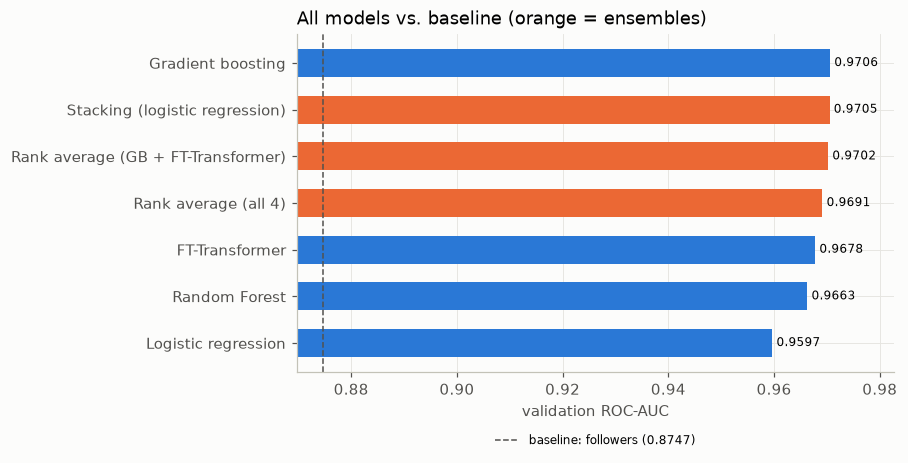

,validation AUC,improvement over baseline
Gradient boosting,0.97060,0.09589
Stacking (logistic regression),0.97050,0.09579
Rank average (GB + FT-Transformer),0.97023,0.09552
Rank average (all 4),0.96914,0.09444
FT-Transformer,0.96778,0.09307
Random Forest,0.96629,0.09159
Logistic regression,0.95966,0.08496


In [7]:
final = pd.Series(results).sort_values()

fig, ax = plt.subplots(figsize=(7, 4))
colors = [ORANGE if name not in MODELS.values() else BLUE for name in final.index]  # orange = ensemble
ax.barh(final.index, final.values - BASELINE + 0.005, left=BASELINE - 0.005, color=colors, height=0.6)
ax.axvline(BASELINE, color=GREY, lw=1, ls="--", label=f"baseline: followers ({BASELINE:.4f})")
for i, v in enumerate(final.values):
    ax.text(v + 0.0008, i, f"{v:.4f}", va="center", fontsize=8)
ax.set_xlim(BASELINE - 0.005, final.max() + 0.012)
ax.set_xlabel("validation ROC-AUC")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15), fontsize=8)
ax.set_title("All models vs. baseline (orange = ensembles)", loc="left")
plt.show()

summary = pd.DataFrame({"validation AUC": final[::-1], "improvement over baseline": final[::-1] - BASELINE}).round(5)
summary

**Interpretation.**
- **Every model clearly beats the baseline** (`artist_followers` alone, 0.8747), by +0.085 to +0.095 AUC.
- **Gradient boosting is the best single model**, followed by the FT-Transformer.
- **The ensembles don't really help here.** Stacking and the GB + FT average land slightly *below* gradient boosting alone (−0.0001 and −0.0004),
  differences the size of random noise on 70,000 validation songs. The rank average of all 4 is even slightly worse, because
  the weaker models pull it down. This matches what we saw in the correlations: the models make very similar mistakes.
- The stacker gives logistic regression a *negative* weight. It uses LR only to correct the others a little, not as a vote of its own.

## 5. Kaggle submission
**Rule:** we only use an ensemble if it beats the best single model by more than 0.001 AUC.
Smaller differences are noise, and then the simpler model is the better choice.

For rank averaging, the submitted "probability" is the average rank. That isn't a calibrated probability,
but AUC only uses the order, so it doesn't need to be.

In [8]:
best_single = max(MODELS.values(), key=lambda name: results[name])
best = summary.index[0]
if best not in MODELS.values() and results[best] - results[best_single] < 0.001:
    print(f"'{best}' is only {results[best] - results[best_single]:+.5f} better than '{best_single}' -> use the simpler model")
    best = best_single
print("submitted model:", best)

if best == "Stacking (logistic regression)":
    test_score = stacker.predict_proba(test_ranks)[:, 1]
elif best == "Rank average (GB + FT-Transformer)":
    test_score = test_ranks[best_two].mean(axis=1)
elif best == "Rank average (all 4)":
    test_score = test_ranks[all_models].mean(axis=1)
else:  # a single model was best
    test_score = test_preds[best]

submission = pd.DataFrame({"id": test_ids, "music_hit": np.asarray(test_score)})
submission.to_csv("results/submission.csv", index=False)
print(submission.shape)
submission.head()

submitted model: Gradient boosting
(87513, 2)


,id,music_hit
0,350052,0.001698
1,350053,0.373179
2,350054,0.380680
3,350055,0.455696
4,350056,0.461733


**Possible next step:** all models were trained on the 80 % dev part only. For the final submission they could be
retrained on 100 % of `train.csv` (with the same settings), which usually gains a little AUC on the leaderboard.